# 🐧 ASSIGNMENT — The Penguin Field Guide (EDA)

| | |
|---|---|
| **Student Name** | Ashub Shafqat |
| **Student ID** | _____________________________ |
| **Due Date** | 10th Sep,2026 |
| **Total Marks** | **100** (+10 bonus) |

---
### 🎬 The scenario
> *You're a **field biologist** at the Palmer Research Station in Antarctica. Your team has measured **344 penguins** across three species — **Adélie, Chinstrap, and Gentoo** — recording bill size, flipper length, and body mass.*
>
> *Next season, junior researchers need to identify species **in the field, from measurements alone.** Your assignment: use EDA to discover each species' "measurement fingerprint" and produce a simple **field guide** for telling them apart.*

### 🎯 What you'll be graded on
Not just working code — **correct analysis and clear, evidence-based conclusions.** Every chart should help answer: *what makes each species distinct?*

### 📤 Submission
Run all cells before submitting (Kernel → Restart & Run All). Answer every **✍️ Written Answer** box in your own words. Save and submit this `.ipynb` file with all outputs visible.

### 📋 Mark breakdown
| Part | Task | Marks |
|---|---|---|
| **A** | Setup & load the data | 10 |
| **B** | Clean the data (justify your choices) | 15 |
| **C** | Categorical EDA (species & islands) | 15 |
| **D** | Numerical EDA (distributions & correlations) | 20 |
| **E** | Species fingerprints (the core analysis) | 25 |
| **F** | Written field guide (your conclusions) | 15 |
| **Bonus** | Identify a mystery penguin | +10 |

---

## Part A — Setup & Load  *(10 marks)*

In [1]:
# TODO (5): import pandas as pd, numpy as np, matplotlib.pyplot as plt, seaborn as sns
# Set seaborn theme to 'whitegrid'.

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style='whitegrid')


In [2]:
# TODO (5): Load the penguins dataset (offline):  df = sns.load_dataset('penguins')
# Print its shape, and show the first 5 rows. Then run df.info().

df = sns.load_dataset('penguins')

print("Shape of dataset:", df.shape)
display(df.head())
df.info()

Shape of dataset: (344, 7)


,species,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex
0,Adelie,Torgersen,39.1,18.7,181.0,3750.0,Male
1,Adelie,Torgersen,39.5,17.4,186.0,3800.0,Female
2,Adelie,Torgersen,40.3,18.0,195.0,3250.0,Female
3,Adelie,Torgersen,NaN,NaN,NaN,NaN,NaN
4,Adelie,Torgersen,36.7,19.3,193.0,3450.0,Female


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 344 entries, 0 to 343
Data columns (total 7 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   species            344 non-null    object 
 1   island             344 non-null    object 
 2   bill_length_mm     342 non-null    float64
 3   bill_depth_mm      342 non-null    float64
 4   flipper_length_mm  342 non-null    float64
 5   body_mass_g        342 non-null    float64
 6   sex                333 non-null    object 
dtypes: float64(4), object(3)
memory usage: 18.9+ KB


## Part B — Clean the Data  *(15 marks)*
Real field data has gaps. Handle them thoughtfully — and **justify** each choice.

In [3]:
# TODO (5): Print the number of missing values in each column.

print("Missing values per column:")
print(df.isna().sum())


Missing values per column:
species               0
island                0
bill_length_mm        2
bill_depth_mm         2
flipper_length_mm     2
body_mass_g           2
sex                  11
dtype: int64


In [4]:
# TODO (10):
# - A few rows are missing ALL measurements → drop those rows.
# - Some rows are missing 'sex' → drop those rows too (we need it later).
# Hint: df = df.dropna().reset_index(drop=True)
# Print the shape before and after.

print("Shape before dropping rows with missing values:", df.shape)
df = df.dropna().reset_index(drop=True)
print("Shape after dropping rows with missing values:", df.shape)


Shape before dropping rows with missing values: (344, 7)
Shape after dropping rows with missing values: (333, 7)


**✍️ Written Answer B (marks for reasoning):** How many rows did you remove, and what % of the data was that? Was dropping them safe? Why?
*Your answer:* _______________

We removed **11 rows** out of the original 344, which is about **3.2% of the dataset**. This was safe to do because:
- 2 of those rows had *every* measurement column missing (bill length/depth, flipper length, body mass) — there is nothing to analyze in those rows, so they carry no usable information.
- The remaining 9 rows were only missing `sex`, but since we need `sex` for later grouping/consistency and it can't be reliably guessed from the other measurements, dropping them is the safer option.
- 3.2% is a very small fraction of the data, so removing these rows is very unlikely to bias our conclusions about species differences, and the sample per species (146 Adélie, 68 Chinstrap, 119 Gentoo) is still large enough for reliable EDA.


## Part C — Categorical EDA  *(15 marks)*
*How many of each species, and where do they live?*

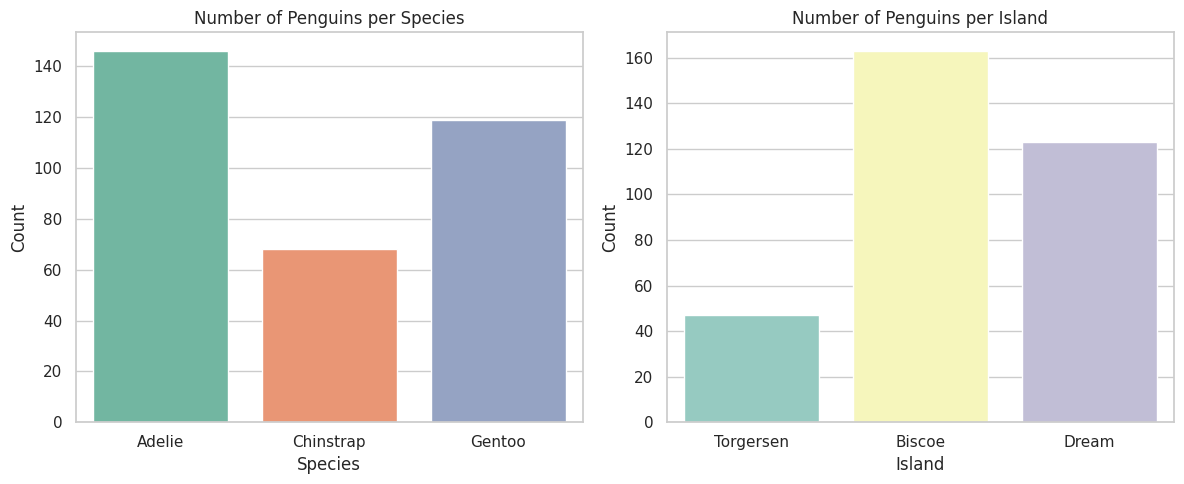

In [5]:
# TODO (8): In a 1×2 grid, plot a countplot of 'species' and a countplot of 'island'.
# Give each a clear title.

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

sns.countplot(data=df, x='species', hue='species', palette='Set2', legend=False, ax=axes[0])
axes[0].set_title('Number of Penguins per Species')
axes[0].set_xlabel('Species')
axes[0].set_ylabel('Count')

sns.countplot(data=df, x='island', hue='island', palette='Set3', legend=False, ax=axes[1])
axes[1].set_title('Number of Penguins per Island')
axes[1].set_xlabel('Island')
axes[1].set_ylabel('Count')

plt.tight_layout()
plt.show()



island     Biscoe  Dream  Torgersen
species                            
Adelie         44     55         47
Chinstrap       0     68          0
Gentoo        119      0          0


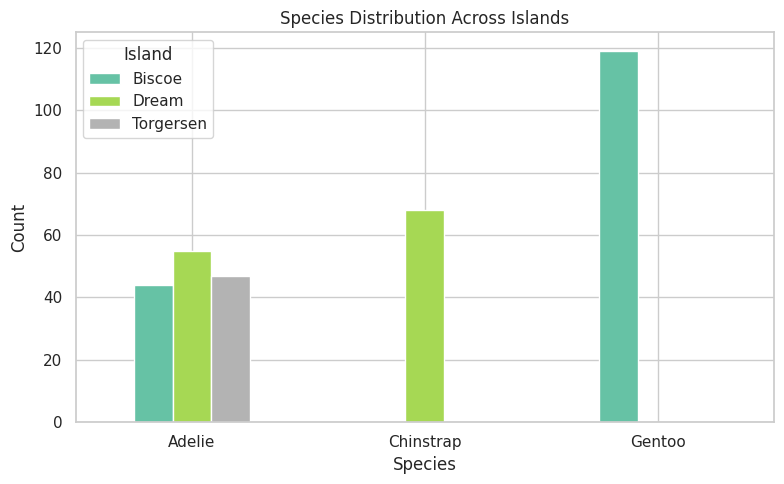

In [6]:
# TODO (7): Make a crosstab of species vs island (pd.crosstab) and plot it as a bar chart.
# Which islands does each species live on?

species_island = pd.crosstab(df['species'], df['island'])
print(species_island)

species_island.plot(kind='bar', figsize=(8, 5), colormap='Set2')
plt.title('Species Distribution Across Islands')
plt.xlabel('Species')
plt.ylabel('Count')
plt.xticks(rotation=0)
plt.legend(title='Island')
plt.tight_layout()
plt.show()


**✍️ Written Answer C:** Which species is the most common? Is any species found on only ONE island? (That's a huge clue for identification.)
*Your answer:* _______________

**Adélie** is the most common species (146 penguins), followed by Gentoo (119) and Chinstrap (68).

Yes - two of the three species are single-island specialists: **Gentoo** penguins are found *only* on Biscoe Island, and **Chinstrap** penguins are found *only* on Dream Island. Only **Adélie** penguins are spread across all three islands (Biscoe, Dream, and Torgersen). This means that if a penguin is spotted on Torgersen, it is almost certainly Adélie, and island alone can rule out two of the three species before we even look at measurements.


## Part D — Numerical EDA  *(20 marks)*
*Understand the four body measurements.*

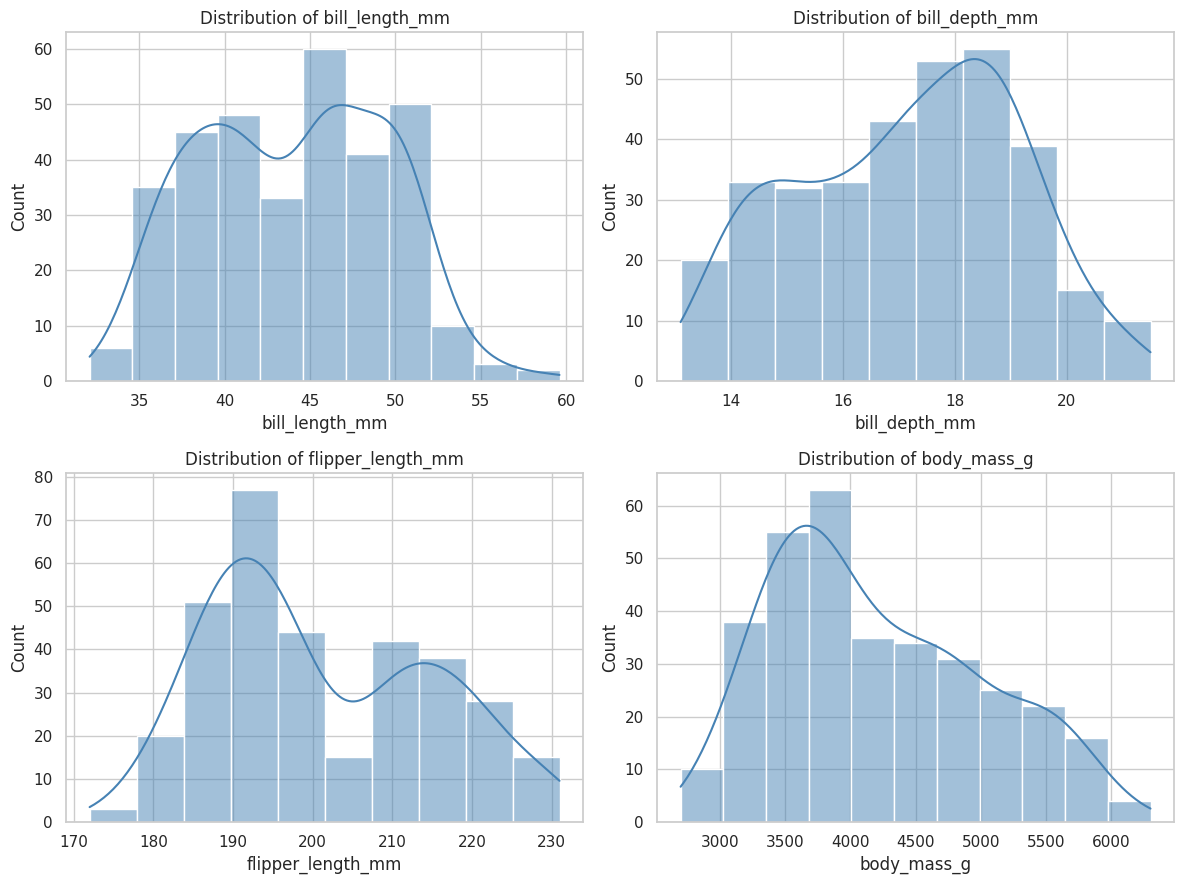

In [7]:
# TODO (10): For each of the 4 measurements
#   (bill_length_mm, bill_depth_mm, flipper_length_mm, body_mass_g),
# plot a histogram with kde=True. Arrange as a 2×2 grid.
# Look: are any distributions clearly split into groups (bumps)? That hints at species!

num_cols = ['bill_length_mm', 'bill_depth_mm', 'flipper_length_mm', 'body_mass_g']

fig, axes = plt.subplots(2, 2, figsize=(12, 9))
axes = axes.flatten()

for i, col in enumerate(num_cols):
    sns.histplot(data=df, x=col, kde=True, ax=axes[i], color='steelblue')
    axes[i].set_title(f'Distribution of {col}')

plt.tight_layout()
plt.show()


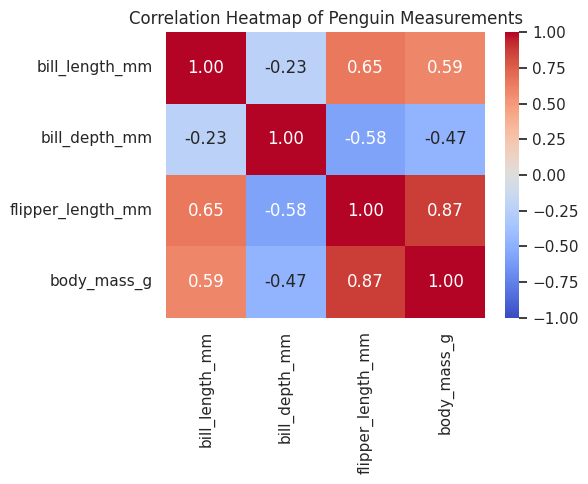

In [8]:
# TODO (10): Plot a correlation heatmap of the 4 numeric measurements (annot=True).
# Which two measurements are most strongly related?

corr = df[num_cols].corr()

plt.figure(figsize=(6, 5))
sns.heatmap(corr, annot=True, cmap='coolwarm', fmt='.2f', vmin=-1, vmax=1)
plt.title('Correlation Heatmap of Penguin Measurements')
plt.tight_layout()
plt.show()



**✍️ Written Answer D:** Which two measurements have the strongest positive correlation, and does that make biological sense (think: bigger penguin → ?)
*Your answer:* _______________

**Flipper length** and **body mass** have the strongest positive correlation (r ≈ 0.87). This makes complete biological sense: flippers are a structural/skeletal feature, so as a penguin's overall body size increases, both its skeleton (and therefore flipper length) and its body mass increase together. A bigger-bodied penguin needs longer flippers to swim efficiently and simply has more body tissue overall, so "bigger penguin → longer flippers AND higher body mass" is exactly the pattern we'd expect from body-size scaling.

Several histograms in Part D (especially bill length and flipper length) also show a clear bimodal/multi-bump shape rather than one smooth curve — a strong early hint that more than one species is mixed into the data.


## Part E — Species Fingerprints  *(25 marks)*  🎯 *the core of the assignment*
*This is where you crack the case: which measurements tell the species apart?*

In [9]:
# TODO (9): Compute the MEAN of each measurement grouped by species.
#   df.groupby('species')[num_cols].mean()
# This table is the heart of your field guide — study it.

species_means = df.groupby('species')[num_cols].mean().round(1)
display(species_means)



,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g
species,,,,
Adelie,38.8,18.3,190.1,3706.2
Chinstrap,48.8,18.4,195.8,3733.1
Gentoo,47.6,15.0,217.2,5092.4


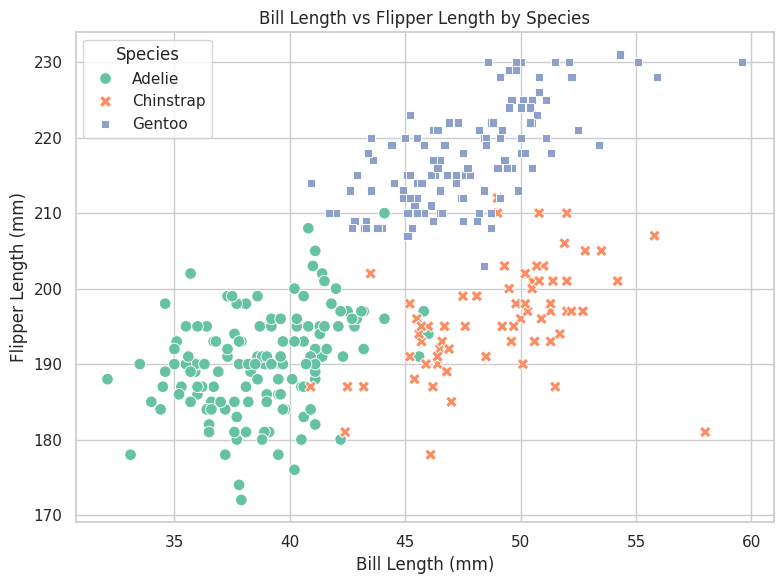

In [10]:
# TODO (8): Make a scatter plot of bill_length_mm (x) vs flipper_length_mm (y),
# coloured by species (hue='species'). Do the species form separate clusters?

plt.figure(figsize=(8, 6))
sns.scatterplot(data=df, x='bill_length_mm', y='flipper_length_mm', hue='species',
                 style='species', s=70, palette='Set2')
plt.title('Bill Length vs Flipper Length by Species')
plt.xlabel('Bill Length (mm)')
plt.ylabel('Flipper Length (mm)')
plt.legend(title='Species')
plt.tight_layout()
plt.show()


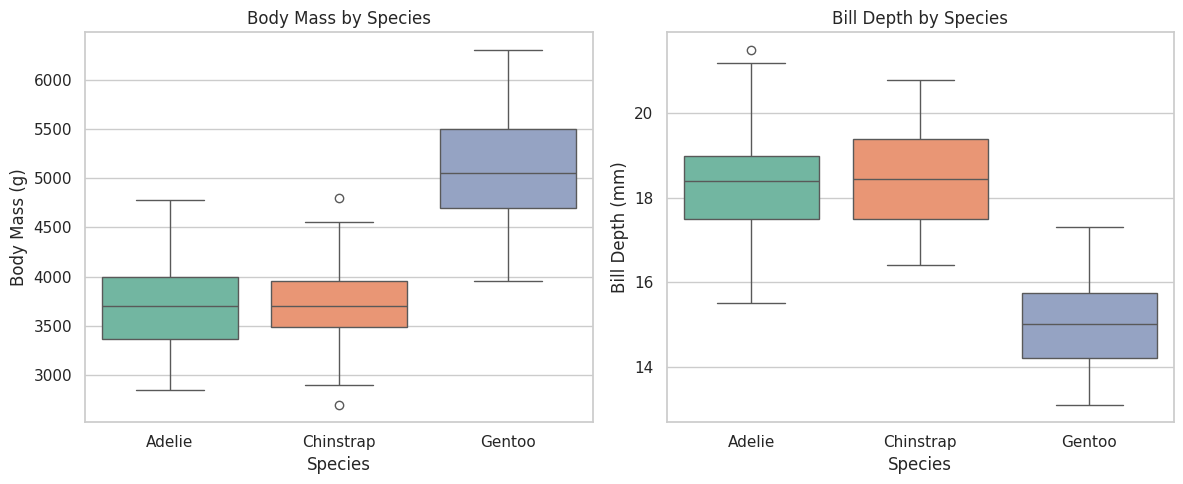

In [11]:
# TODO (8): Make boxplots of body_mass_g by species, and bill_depth_mm by species
# (1×2 grid). Which species is the clear outlier in size?

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

sns.boxplot(data=df, x='species', y='body_mass_g', hue='species', palette='Set2', legend=False, ax=axes[0])
axes[0].set_title('Body Mass by Species')
axes[0].set_xlabel('Species')
axes[0].set_ylabel('Body Mass (g)')

sns.boxplot(data=df, x='species', y='bill_depth_mm', hue='species', palette='Set2', legend=False, ax=axes[1])
axes[1].set_title('Bill Depth by Species')
axes[1].set_xlabel('Species')
axes[1].set_ylabel('Bill Depth (mm)')

plt.tight_layout()
plt.show()

**✍️ Written Answer E:** Describe each species in ONE sentence using measurements. For example: *"Gentoos are the ___ (heaviest/lightest), with the ___ flippers and a ___ bill."* Do this for all three species.

*Adélie:* Adélies are the **smallest-billed** species, with a **short bill (~38.8 mm)**, **short-to-medium flippers (~190 mm)**, and the **lowest body mass (~3706 g)** of the three.

*Chinstrap:* Chinstraps have the **longest, most slender bill (~48.8 mm long, ~18.4 mm deep)**, but flippers (196 mm) and body mass (~3733 g) similar to Adélie — bill length is what sets them apart.

*Gentoo:* Gentoos are the **heaviest** species (5092 g), with the **longest flippers (~217 mm)** and a **noticeably shallow/flat bill (~15.0 mm deep)** compared to the other two species.


## Part F — Your Field Guide  *(15 marks)*
Write a short **field guide** (4–6 sentences) that a junior researcher could use to identify a penguin from measurements alone. Base every rule on your charts. A good guide gives simple decision rules, e.g. *"If flipper length > 210mm, it's almost certainly a Gentoo."*

**✍️ Your Field Guide:**

> 1. **Check flipper length first:** if flipper length is greater than 210 mm, the penguin is almost certainly a **Gentoo** - no other species comes close to this range.
>2. **Check bill depth as a backup for Gentoo:** Gentoos also have a distinctly shallow bill (around 14–16 mm deep), while Adélie and Chinstrap are both around 17–20 mm deep — so a "flat-billed" penguin is a Gentoo.
> 3. **If flipper length is under 200 mm, look at bill length:** a short bill (under ~41 mm) points to **Adélie**, while a long, slender bill (over ~46 mm) with normal bill depth points to **Chinstrap**.
>4. **Use the island as a sanity check:** a penguin spotted on **Biscoe** is very likely Gentoo (or Adélie), one on **Dream** is Adélie or Chinstrap, and one on **Torgersen** is Adélie only — Gentoo and Chinstrap never overlap on the same island.
> 5. **Body mass is a good secondary clue:** Gentoos are noticeably heavier (5 kg average) than Adélie and Chinstrap (~3.7 kg average), so a heavy bird almost rules out the other two species.
6. In short: **big + flat-billed + long-flippered = Gentoo; short bill + smaller body = Adélie; long thin bill + Adélie-sized body = Chinstrap.**






## 🌟 Bonus — Identify the Mystery Penguin  *(+10 marks)*
A researcher measured a penguin but forgot to record its species:

> **bill_length = 46 mm, bill_depth = 15 mm, flipper_length = 217 mm, body_mass = 5000 g**

Using your fingerprints from Part E, decide which species it is — and **justify with the data** (which measurements gave it away?).

,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g
species,,,,
Adelie,38.8,18.3,190.1,3706.2
Chinstrap,48.8,18.4,195.8,3733.1
Gentoo,47.6,15.0,217.2,5092.4
Mystery Penguin,46.0,15.0,217.0,5000.0


Distance of mystery penguin from each species' mean measurements:
{'Adelie': np.float64(1294.1), 'Chinstrap': np.float64(1267.1), 'Gentoo': np.float64(92.4)}


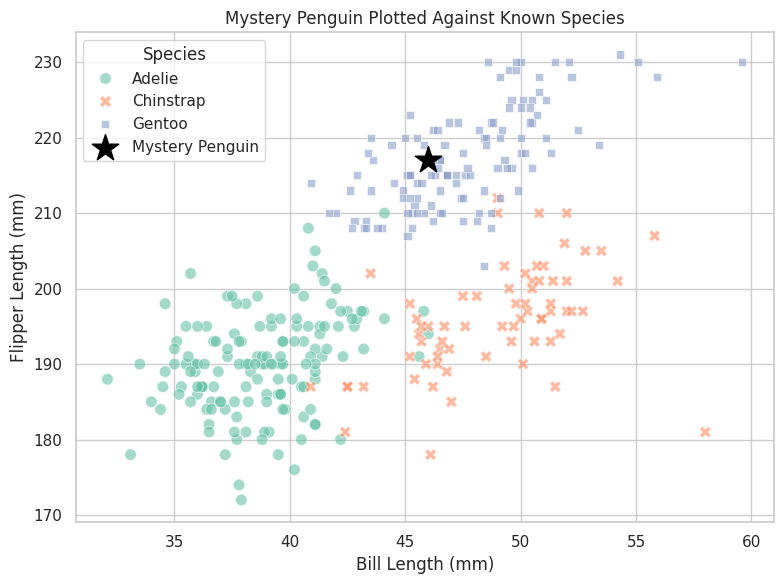

In [12]:
# TODO (bonus): Justify your answer with code — e.g. compare this penguin's numbers
# to the species means, or plot it on top of your scatter from Part E.

mystery = {'bill_length_mm': 46, 'bill_depth_mm': 15, 'flipper_length_mm': 217, 'body_mass_g': 5000}

comparison = species_means.copy()
comparison.loc['Mystery Penguin'] = mystery
display(comparison)

# Euclidean distance from the mystery penguin to each species' mean fingerprint
distances = {}
for sp in species_means.index:
    dist = np.sqrt(sum((species_means.loc[sp, c] - mystery[c]) ** 2 for c in num_cols))
    distances[sp] = round(dist, 1)

print("Distance of mystery penguin from each species' mean measurements:")
print(distances)

# Visualize it on the Part E scatter plot
plt.figure(figsize=(8, 6))
sns.scatterplot(data=df, x='bill_length_mm', y='flipper_length_mm', hue='species',
                 style='species', s=70, palette='Set2', alpha=0.6)
plt.scatter(mystery['bill_length_mm'], mystery['flipper_length_mm'],
            color='black', marker='*', s=400, label='Mystery Penguin')
plt.title('Mystery Penguin Plotted Against Known Species')
plt.xlabel('Bill Length (mm)')
plt.ylabel('Flipper Length (mm)')
plt.legend(title='Species')
plt.tight_layout()
plt.show()


**✍️ Bonus Answer:** This penguin is a **_______**, because _______________

**✍️ Bonus Answer:** This penguin is a **Gentoo**, because its measurements are closest to the Gentoo fingerprint on almost every axis: its flipper length (217 mm) matches the Gentoo average (217.2 mm)almost exactly, its bill depth (15 mm) matches the Gentoo average (~15.0 mm) and is far shallower than the ~18 mm typical of Adélie/Chinstrap, and its body mass (5000 g) is close to the Gentoo average (5092 g) and much heavier than Adélie/Chinstrap (3.7 kg). The distance calculation above confirms this numerically - the mystery penguin's distance to the Gentoo mean is far smaller than its distance to the Adélie or Chinstrap means. Bill length (46 mm) alone might look ambiguous between Chinstrap and Gentoo, but combined with the shallow bill depth, long flippers, and heavy body mass, all the evidence points to **Gentoo**.


---
### ✅ Before you submit
- [-] Every `# TODO` cell has working code
- [-] Every ✍️ Written Answer is filled in
- [-] You ran **Kernel → Restart & Run All** with no errors
- [-] Charts have titles and are readable

*Good luck, field biologist!* 🐧